In [1]:
import os
import cv2
import time
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter

from torch import nn, optim
from torch.utils.data import DataLoader

from torchvision import transforms, datasets
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

import kornia.augmentation as K

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
torch.backends.cudnn.benchmark = True

torch.set_float32_matmul_precision("high")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [3]:
train_path = r"/kaggle/input/datasets/bmuthukumar07/seed-data/data/train"
val_path = r"/kaggle/input/datasets/bmuthukumar07/seed-data/data/val"

In [4]:
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [5]:
train_set = datasets.ImageFolder(train_path, transform=train_transform)
test_set  = datasets.ImageFolder(val_path,   transform=test_transform)

In [6]:
classes = train_set.classes

print("Classes:", classes)

count_train = Counter(train_set.targets)
count_test = Counter(test_set.targets)

print("="*50)
print("Dataset Distribution")
print("="*50)

for i in range(len(classes)):
    print(
        f"{classes[i]:15} "
        f"Train: {count_train[i]:5} "
        f"| Val: {count_test[i]:5}"
    )

print("="*50)

Classes: ['broken', 'discolored', 'pure', 'silkcut']
Dataset Distribution
broken          Train:  4554 | Val:  1116
discolored      Train:  2504 | Val:   611
pure            Train:  5855 | Val:  1428
silkcut         Train:  1427 | Val:   324


In [8]:
BATCH_SIZE = 32
train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True
)

In [9]:
gpu_aug = nn.Sequential(

    K.RandomHorizontalFlip(p=0.5),
    K.RandomRotation(degrees=15.0, p=0.5),
    
    K.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
        p=0.5
    ),

    K.Normalize(
        mean=torch.tensor(
            [0.485, 0.456, 0.406]
        ),
        std=torch.tensor(
            [0.229, 0.224, 0.225]
        )
    )

).to(device)

In [10]:
weights    = ConvNeXt_Tiny_Weights.DEFAULT
base_model = convnext_tiny(weights=weights)

for param in base_model.features[:6].parameters():
    param.requires_grad = False

num_features = base_model.classifier[2].in_features

base_model.classifier[2] = nn.Sequential(
    nn.LayerNorm(num_features),
    nn.Dropout(0.3),
    nn.Linear(num_features, len(classes))
)

model = base_model.to(device)
model = model.to(memory_format=torch.channels_last)

trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel()
    for p in model.parameters()
)

print(f"Trainable: {trainable:,}")
print(f"Total: {total:,}")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 230MB/s] 


Trainable: 15,476,740
Total: 27,824,740


In [11]:
from sklearn.utils.class_weight import compute_class_weight

weight = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_set.targets),
    y=train_set.targets
)

weight = torch.tensor(
    weight,
    dtype=torch.float32
).to(device)

print(weight)

tensor([0.7872, 1.4317, 0.6123, 2.5123], device='cuda:0')


In [12]:


criterion = nn.CrossEntropyLoss(
    weight = weight,
    label_smoothing=0.1
)


optimizer = optim.AdamW(
    [
        {"params": base_model.features[6:].parameters(), "lr": 5e-5},
        {"params": base_model.classifier.parameters(), "lr": 2.5e-4},
    ],
    weight_decay=1e-3
)
epochs = 20

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs,
    eta_min=1e-6
)

In [13]:
scaler = torch.amp.GradScaler("cuda")

train_acc_history  = []
val_acc_history    = []
train_loss_history = []
val_loss_history   = []

counter = 0
patience = 7

best_accuracy = 0.0
best_val_loss = float('inf')

for epoch in range(epochs):

    start_time = time.time()

    # --- Train ---
    model.train()
    running_loss = 0.0
    correct = total = 0

    for images, labels in train_loader:

        images = images.to(device, memory_format=torch.channels_last, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        images = gpu_aug(images)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):
            outputs = model(images)
            loss    = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        _, predicted  = torch.max(outputs, 1)
        total        += labels.size(0)
        correct      += (predicted == labels).sum().item()

    train_acc  = correct / total
    train_loss = running_loss / len(train_loader)
    train_acc_history.append(train_acc)
    train_loss_history.append(train_loss)

    # --- Validate ---
    model.eval()
    correct = total = 0
    val_running_loss = 0.0
    y_true, y_pred   = [], []

    with torch.no_grad():
        for images, labels in test_loader:

            images = images.to(device, memory_format=torch.channels_last, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast("cuda"):
                outputs = model(images)
                loss    = criterion(outputs, labels)

            val_running_loss += loss.item()
            _, predicted      = torch.max(outputs, 1)
            total            += labels.size(0)
            correct          += (predicted == labels).sum().item()

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_acc  = correct / total
    val_loss = val_running_loss / len(test_loader)
    val_acc_history.append(val_acc)
    val_loss_history.append(val_loss)

    scheduler.step()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_accuracy = val_acc
        torch.save(model.state_dict(), "best_convnext_tiny.pth")
        counter = 0
    else:
        counter+=1
        if counter >= patience:
            print(f"\nEarly stopping at epoch {epoch+1}")
            break

    elapsed_time = time.time() - start_time
    print(
        f"Epoch [{epoch+1}/{epochs}]  "
        f"Train Acc: {train_acc:.4f}  Val Acc: {val_acc:.4f}  "
        f"Train Loss: {train_loss:.4f}  Val Loss: {val_loss:.4f}  "
        f"Time: {elapsed_time/60:.2f} min"
    )

print(f"\nBest Val Loss: {best_val_loss:.4f}  |  Val Acc at best: {best_accuracy:.4f}")

Epoch [1/20]  Train Acc: 0.6093  Val Acc: 0.6539  Train Loss: 1.0770  Val Loss: 1.1109  Time: 1.20 min
Epoch [2/20]  Train Acc: 0.7121  Val Acc: 0.7232  Train Loss: 0.9220  Val Loss: 1.0243  Time: 0.71 min
Epoch [3/20]  Train Acc: 0.7511  Val Acc: 0.7413  Train Loss: 0.8684  Val Loss: 1.0070  Time: 0.73 min
Epoch [4/20]  Train Acc: 0.7745  Val Acc: 0.7502  Train Loss: 0.8253  Val Loss: 0.9926  Time: 0.72 min
Epoch [5/20]  Train Acc: 0.7927  Val Acc: 0.7453  Train Loss: 0.7875  Val Loss: 1.0059  Time: 0.72 min
Epoch [6/20]  Train Acc: 0.8196  Val Acc: 0.7517  Train Loss: 0.7468  Val Loss: 1.0072  Time: 0.71 min
Epoch [7/20]  Train Acc: 0.8399  Val Acc: 0.7473  Train Loss: 0.7167  Val Loss: 1.0316  Time: 0.72 min
Epoch [8/20]  Train Acc: 0.8601  Val Acc: 0.7591  Train Loss: 0.6858  Val Loss: 1.0139  Time: 0.72 min
Epoch [9/20]  Train Acc: 0.8782  Val Acc: 0.7617  Train Loss: 0.6541  Val Loss: 1.0140  Time: 0.72 min
Epoch [10/20]  Train Acc: 0.8924  Val Acc: 0.7479  Train Loss: 0.6398  Va

In [ ]:
# Load saved weights
WEIGHTS_PATH = "//kaggle/working/best_convnext_tiny.pth"

model.load_state_dict(
    torch.load(
        WEIGHTS_PATH,
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Saved weights loaded successfully!")

Saved weights loaded successfully!


In [15]:
%pip install -q grad-cam shap lime captum scikit-learn seaborn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter
from skimage.segmentation import mark_boundaries

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

from captum.attr import IntegratedGradients, Occlusion
import shap
from lime import lime_image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 533.6 kB/s eta 0:00:00 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 2.6 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [16]:
model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        probabilities = F.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

if "class_names" not in globals():
    class_names = test_loader.dataset.classes

num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Test samples:", len(all_labels))

Classes: ['broken', 'discolored', 'pure', 'silkcut']
Number of classes: 4
Test samples: 3479


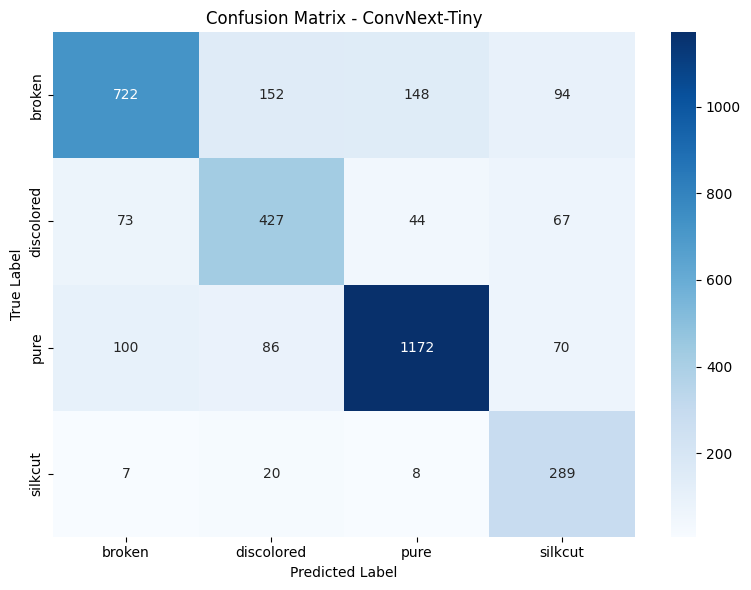

In [17]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - ConvNext-Tiny")
plt.tight_layout()
plt.show()

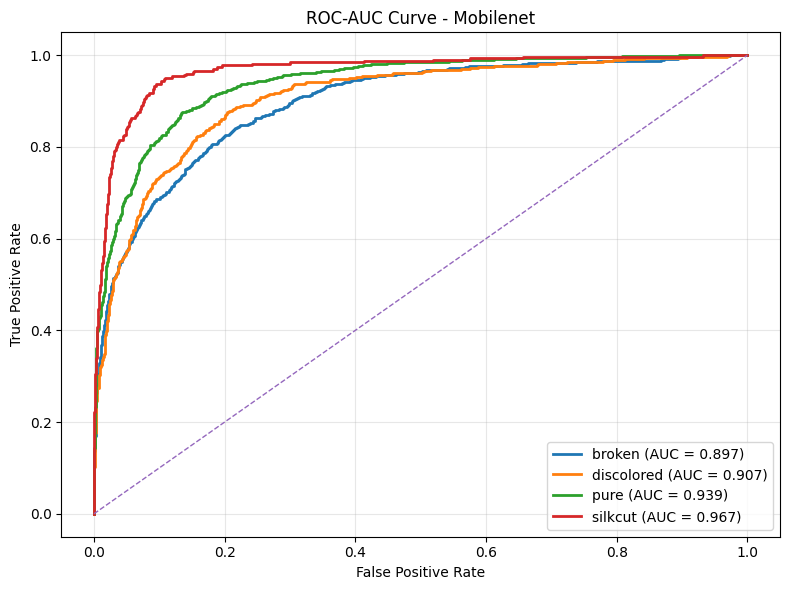

In [18]:
y_true_onehot = np.eye(num_classes)[all_labels]

plt.figure(figsize=(8, 6))

for i in range(num_classes):
    fpr, tpr, _ = roc_curve(
        y_true_onehot[:, i],
        all_probabilities[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve - Mobilenet")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

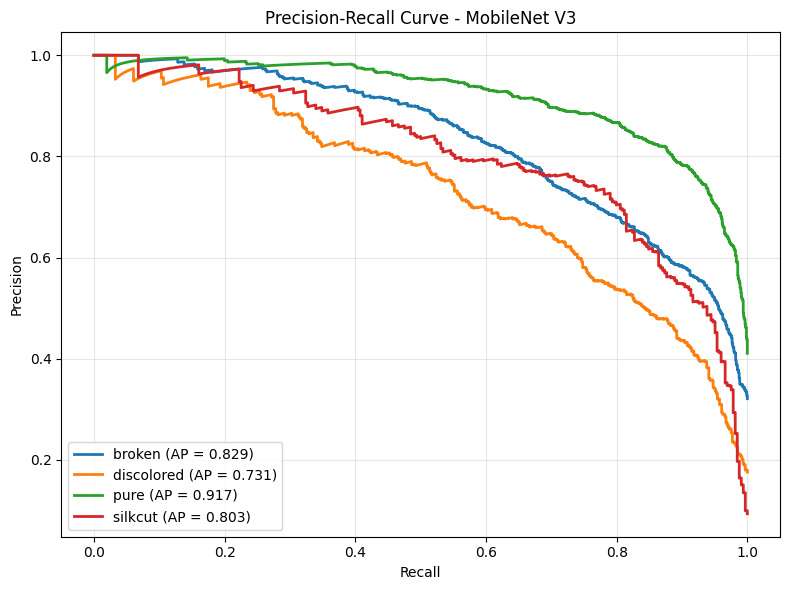

In [19]:
plt.figure(figsize=(8, 6))

for i in range(num_classes):
    precision, recall, _ = precision_recall_curve(
        y_true_onehot[:, i],
        all_probabilities[:, i]
    )

    ap = average_precision_score(
        y_true_onehot[:, i],
        all_probabilities[:, i]
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{class_names[i]} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - MobileNet V3")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
model.eval()

xai_image = None
xai_label = None
xai_prediction = None

for images, labels in test_loader:
    images = images.to(device, non_blocking=True)

    with torch.no_grad():
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

    correct_indices = torch.where(predictions == labels.to(device))[0]

    if len(correct_indices) > 0:
        idx = correct_indices[0].item()

        xai_image = images[idx:idx + 1]
        xai_label = labels[idx].item()
        xai_prediction = predictions[idx].item()
        break

if xai_image is None:
    images, labels = next(iter(test_loader))

    xai_image = images[0:1].to(device)
    xai_label = labels[0].item()

    with torch.no_grad():
        xai_prediction = model(xai_image).argmax(dim=1).item()

print("True class:", class_names[xai_label])
print("Predicted class:", class_names[xai_prediction])

True class: broken
Predicted class: broken


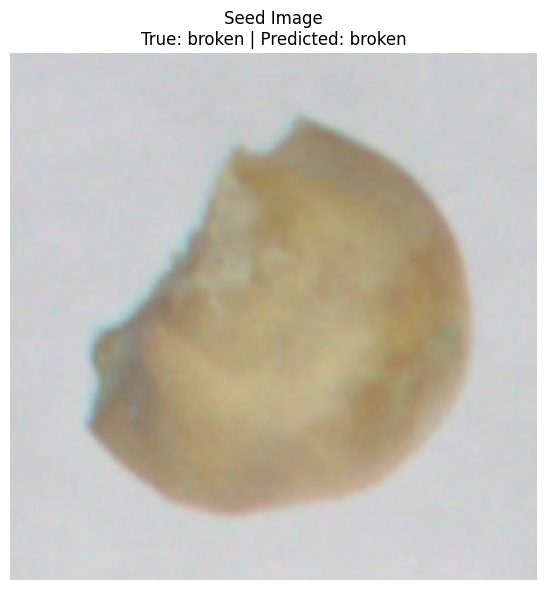

In [21]:

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_display = (
    xai_image[0]
    .detach()
    .cpu()
    .permute(1, 2, 0)
    .numpy()
)

# Properly undo ImageNet normalization
image_display = (
    image_display * std
) + mean

image_display = np.clip(
    image_display,
    0,
    1
)

plt.figure(figsize=(6, 6))

plt.imshow(image_display)

plt.axis("off")

plt.title(
    f"Seed Image\n"
    f"True: {class_names[xai_label]} | "
    f"Predicted: {class_names[xai_prediction]}"
)

plt.tight_layout()
plt.show()

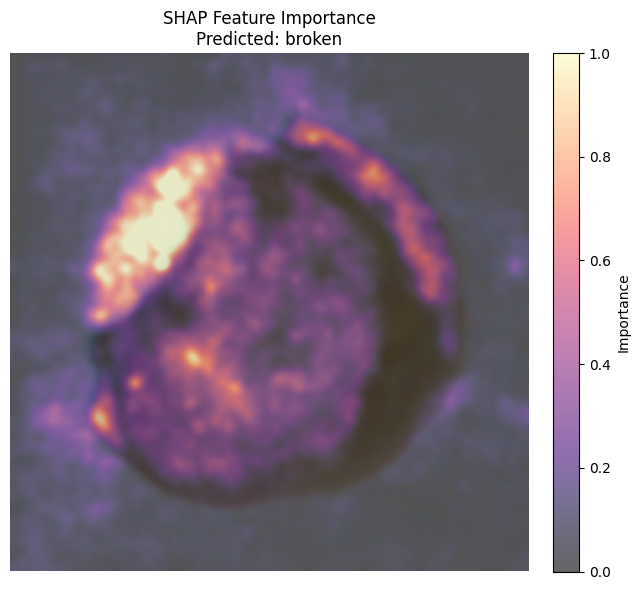

In [23]:
model.eval()

background = next(iter(test_loader))[0][:2].to(device)

class SHAPTargetModel(nn.Module):

    def __init__(self, model, target_class):
        super().__init__()
        self.model = model
        self.target_class = target_class

    def forward(self, x):
        output = self.model(x)

        return output[
            :,
            self.target_class:self.target_class + 1
        ]


shap_model = SHAPTargetModel(
    model,
    xai_prediction
).to(device)

explainer = shap.GradientExplainer(
    shap_model,
    background
)

shap_values = explainer.shap_values(
    xai_image
)

if isinstance(shap_values, list):
    shap_values = shap_values[0]

shap_values = np.asarray(shap_values)

# Remove unnecessary dimensions
shap_values = np.squeeze(shap_values)

if shap_values.ndim == 3:

    if shap_values.shape[0] in [1, 3]:
        shap_map = np.mean(
            np.abs(shap_values),
            axis=0
        )
    else:
        shap_map = np.mean(
            np.abs(shap_values),
            axis=-1
        )

# Smooth pixel-level noise
shap_map = gaussian_filter(
    shap_map,
    sigma=2
)

# Robust normalization
low = np.percentile(
    shap_map,
    5
)

high = np.percentile(
    shap_map,
    99
)

shap_map = np.clip(
    (shap_map - low) / (high - low + 1e-8),
    0,
    1
)

plt.figure(figsize=(7, 6))

plt.imshow(
    image_display
)

plt.imshow(
    shap_map,
    cmap="magma",
    alpha=0.60,
    vmin=0,
    vmax=1
)

plt.axis("off")

plt.title(
    f"SHAP Feature Importance\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Importance"
)

plt.tight_layout()
plt.show()

  0%|          | 0/1000 [00:00<?, ?it/s]

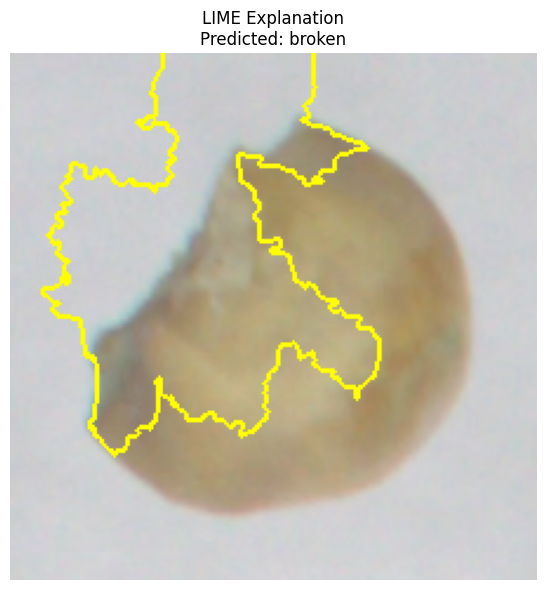

In [24]:
# ============================================================
# IMPROVED LIME
# ============================================================

def lime_predict(images):

    batch = []

    for image in images:

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        image = image.permute(
            2, 0, 1
        )

        image = image / 255.0

        image = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )(image)

        batch.append(image)

    batch = torch.stack(batch).to(device)

    with torch.no_grad():

        outputs = model(batch)

        probabilities = F.softmax(
            outputs,
            dim=1
        )

    return probabilities.cpu().numpy()


lime_explainer = lime_image.LimeImageExplainer(
    verbose=False
)

lime_input = (
    image_display * 255
).astype(np.uint8)

lime_result = lime_explainer.explain_instance(
    lime_input,
    lime_predict,
    top_labels=1,
    hide_color=0,
    num_samples=1000
)

lime_label = lime_result.top_labels[0]

lime_result_image, lime_mask = (
    lime_result.get_image_and_mask(
        lime_label,
        positive_only=True,
        num_features=8,
        hide_rest=False
    )
)

# Create clean boundary visualization
lime_boundary = mark_boundaries(
    lime_result_image,
    lime_mask,
    color=(1, 1, 0),
    mode="thick"
)

plt.figure(figsize=(7, 6))

plt.imshow(
    lime_boundary
)

plt.axis("off")

plt.title(
    f"LIME Explanation\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.tight_layout()
plt.show()

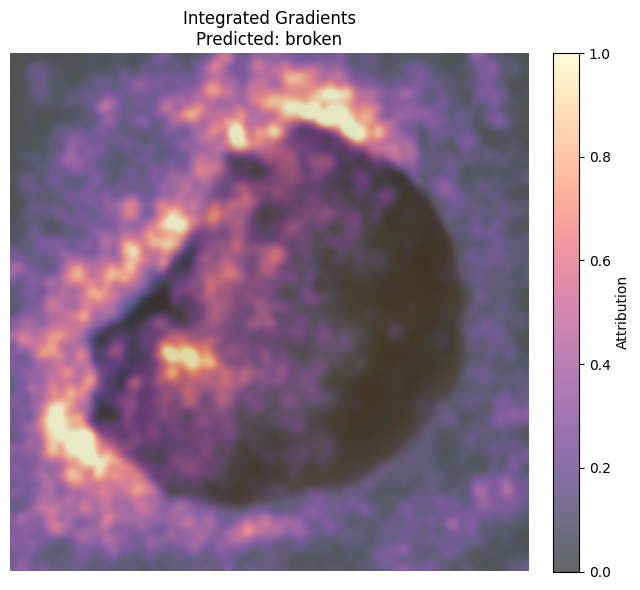

In [25]:
model.eval()

ig = IntegratedGradients(model)

baseline = torch.zeros_like(
    xai_image
)

ig_attributions = ig.attribute(
    xai_image,
    baselines=baseline,
    target=xai_prediction,
    n_steps=64
)

ig_map = (
    ig_attributions[0]
    .detach()
    .cpu()
    .numpy()
)

# Channel aggregation
ig_map = np.mean(
    np.abs(ig_map),
    axis=0
)

# Remove high-frequency noise
ig_map = gaussian_filter(
    ig_map,
    sigma=2
)

# Robust normalization
low = np.percentile(
    ig_map,
    5
)

high = np.percentile(
    ig_map,
    99
)

ig_map = np.clip(
    (ig_map - low) /
    (high - low + 1e-8),
    0,
    1
)

plt.figure(figsize=(7, 6))

plt.imshow(
    image_display
)

plt.imshow(
    ig_map,
    cmap="magma",
    alpha=0.60,
    vmin=0,
    vmax=1
)

plt.axis("off")

plt.title(
    f"Integrated Gradients\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Attribution"
)

plt.tight_layout()
plt.show()

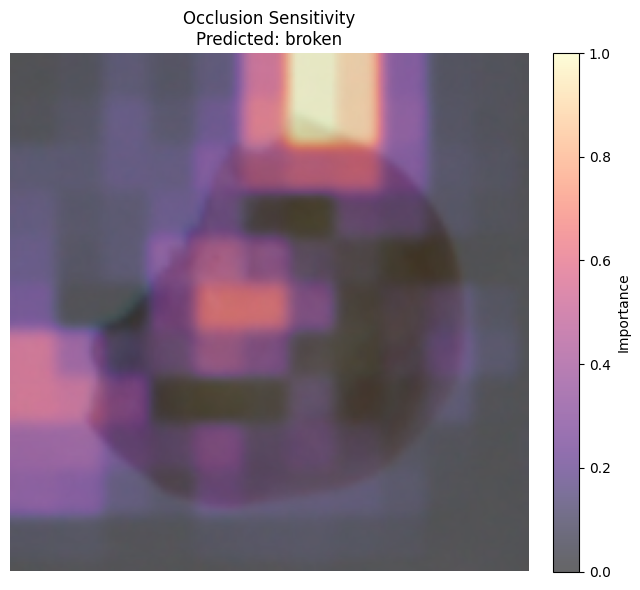

In [26]:
# ============================================================
# IMPROVED OCCLUSION SENSITIVITY
# ============================================================

model.eval()

occlusion = Occlusion(model)

occlusion_attributions = occlusion.attribute(
    xai_image,
    target=xai_prediction,
    strides=(3, 20, 20),
    sliding_window_shapes=(3, 40, 40),
    baselines=0
)

occlusion_map = (
    occlusion_attributions[0]
    .detach()
    .cpu()
    .numpy()
)

occlusion_map = np.mean(
    np.abs(occlusion_map),
    axis=0
)

# Smooth the grid effect
occlusion_map = gaussian_filter(
    occlusion_map,
    sigma=3
)

# Robust normalization
low = np.percentile(
    occlusion_map,
    5
)

high = np.percentile(
    occlusion_map,
    99
)

occlusion_map = np.clip(
    (occlusion_map - low) /
    (high - low + 1e-8),
    0,
    1
)

plt.figure(figsize=(7, 6))

plt.imshow(
    image_display
)

plt.imshow(
    occlusion_map,
    cmap="magma",
    alpha=0.60,
    vmin=0,
    vmax=1
)

plt.axis("off")

plt.title(
    f"Occlusion Sensitivity\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Importance"
)

plt.tight_layout()
plt.show()